# Member 1 — FT-Transformer: formal nested development evaluation

This notebook supersedes the earlier controlled-screening estimate for group comparison. The historical notebook and artifacts remain separate. The authoritative eight-candidate registry is `configs/models/ft_transformer.yaml`.

FT-Transformer combines numerical feature tokens and categorical embeddings using attention. Mixed HR predictors suit this tabular architecture, but extra capacity does not guarantee predictive signal. Numerical standardization and categorical vocabularies are fitted only on training rows. Missing/unknown categories have reserved representations; identifiers, raw hire dates and the target are excluded from predictors.

## Tuning and validation
Each frozen outer fold holds out 16,000 development records. Its 64,000 training records are split into 54,400 inner-training and 9,600 inner-validation records. FT01–FT08 vary model depth, embedding width, attention heads, learning rate, and unweighted versus fold-local positive-class weighting. Each uses inner AP early stopping (100 epoch cap, patience 15). The winning inner-AP configuration is refitted with fresh preprocessing and fresh weights on all 64,000 outer-training records for its selected epoch count. Outer validation is prediction-only. Internal candidate selection is repeated independently for all five folds: 40 candidate evaluations plus five winner refits.

A fixed seed does not guarantee identical results across hardware and library versions. Runtime versions and selection evidence are preserved. The 20,000 formal holdout records are excluded from all fitting and scoring; only their IDs are used to exclude their CSV rows. Full final model refit remains a later group decision.


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / "configs/feature_contract.yaml").exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.models.config import load_model_config
from src.models.ft_transformer_execution import run,load_formal_ft_input
pd.set_option("display.max_columns",None)
config=load_model_config(ROOT / "configs/models/ft_transformer.yaml",strict_schema=True)
display(pd.DataFrame([dict(candidate_id=c["id"],**c["params"]) for c in config["candidates"]]))


,candidate_id,n_blocks,d_block,attention_n_heads,ffn_d_hidden,learning_rate,ffn_dropout,weighting
0,FT01,3,64,4,128,0.0010,0.1,none
1,FT02,3,64,4,128,0.0010,0.1,dynamic_ratio
2,FT03,2,64,4,128,0.0010,0.1,none
3,FT04,2,64,4,128,0.0010,0.1,dynamic_ratio
4,FT05,3,64,4,128,0.0001,0.1,none
5,FT06,3,64,4,128,0.0001,0.1,dynamic_ratio
6,FT07,3,128,8,256,0.0010,0.1,none
7,FT08,3,128,8,256,0.0010,0.1,dynamic_ratio


## Execute or load verified formal results
Set `RUN_TRAINING=True` for deliberate execution/resumption of the full experiment. The default loads its checksum-validated completed evidence without repeating training. Missing evidence raises an error rather than falling back to historical results.


In [2]:
RUN_TRAINING=False
if RUN_TRAINING:run(ROOT)
oof,fold_metrics,summary=load_formal_ft_input(ROOT)
out=ROOT / "results/models/ft_transformer/strict_nested"
selection=pd.read_csv(out / "candidate_selection.csv")
display(selection)
display(fold_metrics)
display(pd.DataFrame([summary]))

,outer_fold,candidate_id,inner_ap,selected_epoch_count,weighting,fit_time_seconds
0,1,FT01,0.106393,16,none,81.102429
1,1,FT02,0.108877,16,dynamic_ratio,74.378143
2,1,FT03,0.106501,32,none,82.824045
3,1,FT04,0.107140,28,dynamic_ratio,72.597910
4,1,FT05,0.107985,2,none,40.084606
5,1,FT06,0.107047,3,dynamic_ratio,41.942914
6,1,FT07,0.105861,22,none,161.735435
7,1,FT08,0.106288,15,dynamic_ratio,142.627056
8,2,FT01,0.101053,16,none,79.015480
9,2,FT02,0.103633,25,dynamic_ratio,103.099105


,fold,fit_time_seconds,predict_time_seconds,selected_candidate,selected_epoch_count,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,1,745.100103,0.196453,FT02,16,0.096581,0.493389,0.083598,0.049344,0.062058,0.494601,0.850750,0.242686,13533,866,1522,79,945,0.059062
1,2,684.240823,0.199332,FT05,1,0.101352,0.505661,0.000000,0.000000,0.000000,0.500000,0.899937,0.090118,14399,0,1601,0,0,0.000000
2,3,633.130631,0.192161,FT02,17,0.095313,0.484555,0.095386,0.480025,0.159147,0.486748,0.492125,0.252314,7105,7293,833,769,8062,0.503875
3,4,693.827556,0.145339,FT03,36,0.100386,0.495808,0.000000,0.000000,0.000000,0.500000,0.899875,0.090162,14398,0,1602,0,0,0.000000
4,5,687.235968,0.208957,FT01,30,0.096695,0.490546,0.000000,0.000000,0.000000,0.500000,0.899875,0.090150,14398,0,1602,0,0,0.000000


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,model_name,cv_mean_ap,cv_std_ap,cv_mean_roc_auc,total_fit_time_seconds,total_predict_time_seconds,development_rows,outer_folds,candidate_evaluations,formal_holdout_used,final_model_frozen,protocol
0,0.098648,0.49798,0.094149,0.105894,0.099677,0.496281,0.808512,0.153086,63833,8159,7160,848,9007,0.112587,FT-Transformer,0.098065,0.002638,0.493992,3443.535081,0.942243,80000,5,40,False,False,strict_nested_eight_candidate_selection


## Evaluation and comparison across candidate varieties
Average Precision is primary at ~10% positive prevalence; the no-skill reference is ~.1001. ROC-AUC compares ranking across both classes (chance .5); Brier measures probability error (lower is better). Recall, precision, F1 and balanced accuracy describe a clearly fixed .50 threshold. Fold standard deviations describe variability, not confidence intervals. Candidate inner scores support within-fold selection; their means below are descriptive, not unbiased outer performance estimates for each fixed candidate. The outer scores evaluate the nested selection procedure.


,mean_inner_ap,sd_inner_ap,mean_selected_epochs
candidate_id,,,
FT01,0.103876,0.002559,17.4
FT02,0.104741,0.003397,16.6
FT03,0.104297,0.002394,22.4
FT04,0.102374,0.002847,16.8
FT05,0.103325,0.003050,1.8
FT06,0.102718,0.002874,2.8
FT07,0.103019,0.003253,14.8
FT08,0.102331,0.002848,8.0


,fold,selected_candidate,selected_epoch_count,average_precision,roc_auc,recall,f1
0,1,FT02,16,0.096581,0.493389,0.049344,0.062058
1,2,FT05,1,0.101352,0.505661,0.000000,0.000000
2,3,FT02,17,0.095313,0.484555,0.480025,0.159147
3,4,FT03,36,0.100386,0.495808,0.000000,0.000000
4,5,FT01,30,0.096695,0.490546,0.000000,0.000000


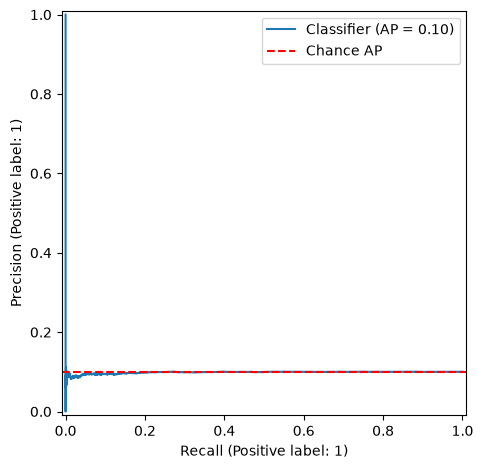

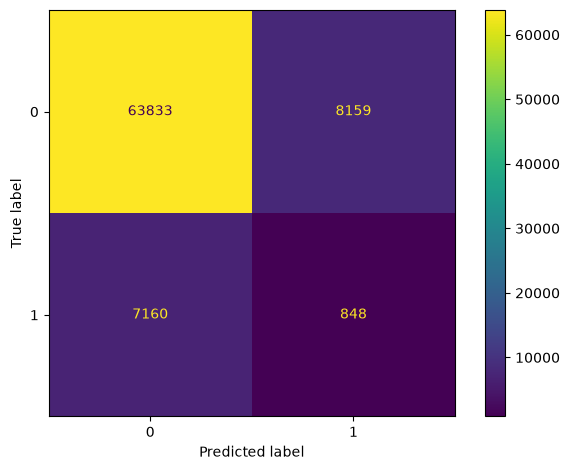

Primary mean fold AP: 0.09806541461164146 Pooled AP: 0.09864796531239689 ROC-AUC: 0.4979796229231931


In [3]:
display(selection.groupby("candidate_id").agg(mean_inner_ap=("inner_ap","mean"),sd_inner_ap=("inner_ap","std"),mean_selected_epochs=("selected_epoch_count","mean")))
display(fold_metrics[["fold","selected_candidate","selected_epoch_count","average_precision","roc_auc","recall","f1"]])
from sklearn.metrics import PrecisionRecallDisplay,ConfusionMatrixDisplay
PrecisionRecallDisplay.from_predictions(oof.y_true,oof.y_probability)
plt.axhline(oof.y_true.mean(),linestyle="--",color="red",label="Chance AP");plt.legend();plt.tight_layout();plt.savefig(out / "precision_recall_curve.png",dpi=150);plt.show()
ConfusionMatrixDisplay.from_predictions(oof.y_true,oof.y_pred_0_5)
plt.tight_layout();plt.savefig(out / "confusion_matrix.png",dpi=150);plt.show()
print("Primary mean fold AP:",summary["cv_mean_ap"],"Pooled AP:",summary["average_precision"],"ROC-AUC:",summary["roc_auc"])

## Limitations and group handoff
Interpret the numerical AP against chance and fold variability; do not equate a small ranking lead with a useful retention tool. Weighted loss may change probability calibration substantially, so calibration and threshold choices require separate development-only analysis. Attention is not a causal explanation. A bounded eight-candidate search is not a global optimum guarantee, and one inner split adds selection variance.

The formal group input is `results/models/ft_transformer/strict_nested/oof_predictions.csv`. The loader validates config/adapter/split provenance and artifact checksums, accepting LF and CRLF representations. Group comparison must use the same frozen development folds and mean fold AP as its primary ranking metric. No model is automatically selected for deployment or final holdout merely because it ranks first.
